In [10]:
import sys
sys.path.append("..")  # make DS/ importable so `scratch` is found

In [ ]:
# - Nearest neighboures is one of the simplest preidctive models there is.
# - It makes no mathematical assumptions, and doesnt require any sort of heavy machinery
# - only requires;
# 1. Some notion of distance
# 2. An assumption that points that are close to one another are similar

# K = ho wmany neighbours to consider when making a prediction
# Nearest = the ones that are closest or most similar
# Neighbor = the other points in the dataset that are close to the point we are trying to predict

# KNN - makes predictions based on similarities in the data.
# - It's a supervised learning algorithm, meaning it requires a labelled dataset to learn from.
# - It can be used for both classification (predicting discrete labels like "spam" or "not spam") and regression tasks (predicting continuous values like "price" or "temperature").
# - It is called a `lazy learner` because it doesn't learn a model during training. Instead, it memorizes the training data and makes predictions on-the-fly during inference.

In [2]:
from typing import List
from collections import Counter

In [ ]:
# if we pick a number K like 3 or 5, and want to clarify some new data point;
# find the 'k nearest' labeled points and let them vote on the new output

# Implement a function that counts votes.

def raw_majority_vote(labels: List[str]) -> str:
    votes = Counter(labels)
    winner, _ = votes.most_common(1)[0]
    return winner

assert raw_majority_vote(['a', 'b', 'c', 'b']) == 'b'

# NB: Doesn't do anything intelligent with ties (keys with same value)
# - Incase of ties, we have several options
# 1. Pick one of the winners at random
# 2. Weight the votes by distance and pick the weighted winner
# 3. Reduce k until we find a unique winner

# 3rd

def majority_vote(labels: List[str]) -> str:
    """Assumes that labels are ordered from neares to farthest"""
    vote_counts = Counter(labels)
    winner, winner_count = vote_counts.most_common(1)[0]
    num_winners = len([
        count
        for count in vote_counts.values()
        if count == winner_count
    ])
    if num_winners == 1:
        return winner                       # unique winner, so return
    else:
        return majority_vote(labels[:-1])   # try again without the farthest

# Tie, so look at first 4, then 'b'
assert majority_vote(['a', 'b', 'c', 'b', 'a']) == 'b'

# The approach works eventually, since in the worst case we go all the way down to just one label, at which that point wins
# With this function it's easy to create a classifier:

from typing import NamedTuple
from scratch.linear_algebra import Vector, distance


class LebaledPoint(NamedTuple):
    point: Vector
    label: str

def knn_classify(
        k: int,
        labeled_points: List[LebaledPoint],
        new_point: Vector
    ) -> str:
    # Order the label points from nearest to farthest
    by_distance = sorted(
        labeled_points,
        key=lambda lp: distance(lp.point, new_point)
    )
    # Find the labels for the k closest
    k_nearest_labels = [lp.label for lp in by_distance[:k]]
    # and let them vote for the most popular label
    return majority_vote(k_nearest_labels)

# The lambda is equivalent to the following function:
# def distance_from_new_point(lp: LebaledPoint) -> float:
#     return distance(lp.point, new_point)

In [15]:
# THE IRIS DATASET

# iris.dat data is comma-separated, with fields
# [sepal_length, sepal_width, petal_length, petal_width, class]

# Build a model that can predict the class(species) from the first four measurements

from typing import Dict
import csv
from collections import defaultdict

def parse_iris_row(row: List[str]) -> LebaledPoint:
    """"""
    measurements = [float(value) for value in row[:-1]]
    label = row[-1].split("-")[-1] # class is e.g. "Iris-virginica"; we just want "virginica"
    return LebaledPoint(measurements, label)

with open("iris.data") as f:
    reader = csv.reader(f)
    iris_data = [
        parse_iris_row(row) 
        for row in reader
        if row
    ]

# We'll also group just the points by species/label so we can plot them
points_by_species : Dict[str, List[Vector]] = defaultdict(list)
for iris in iris_data:
    points_by_species[iris.label].append(iris.point)

print(points_by_species)

defaultdict(<class 'list'>, {'setosa': [[5.1, 3.5, 1.4, 0.2], [4.9, 3.0, 1.4, 0.2], [4.7, 3.2, 1.3, 0.2], [4.6, 3.1, 1.5, 0.2], [5.0, 3.6, 1.4, 0.2], [5.4, 3.9, 1.7, 0.4], [4.6, 3.4, 1.4, 0.3], [5.0, 3.4, 1.5, 0.2], [4.4, 2.9, 1.4, 0.2], [4.9, 3.1, 1.5, 0.1], [5.4, 3.7, 1.5, 0.2], [4.8, 3.4, 1.6, 0.2], [4.8, 3.0, 1.4, 0.1], [4.3, 3.0, 1.1, 0.1], [5.8, 4.0, 1.2, 0.2], [5.7, 4.4, 1.5, 0.4], [5.4, 3.9, 1.3, 0.4], [5.1, 3.5, 1.4, 0.3], [5.7, 3.8, 1.7, 0.3], [5.1, 3.8, 1.5, 0.3], [5.4, 3.4, 1.7, 0.2], [5.1, 3.7, 1.5, 0.4], [4.6, 3.6, 1.0, 0.2], [5.1, 3.3, 1.7, 0.5], [4.8, 3.4, 1.9, 0.2], [5.0, 3.0, 1.6, 0.2], [5.0, 3.4, 1.6, 0.4], [5.2, 3.5, 1.5, 0.2], [5.2, 3.4, 1.4, 0.2], [4.7, 3.2, 1.6, 0.2], [4.8, 3.1, 1.6, 0.2], [5.4, 3.4, 1.5, 0.4], [5.2, 4.1, 1.5, 0.1], [5.5, 4.2, 1.4, 0.2], [4.9, 3.1, 1.5, 0.1], [5.0, 3.2, 1.2, 0.2], [5.5, 3.5, 1.3, 0.2], [4.9, 3.1, 1.5, 0.1], [4.4, 3.0, 1.3, 0.2], [5.1, 3.4, 1.5, 0.2], [5.0, 3.5, 1.3, 0.3], [4.5, 2.3, 1.3, 0.3], [4.4, 3.2, 1.3, 0.2], [5.0, 3.5, 1.6

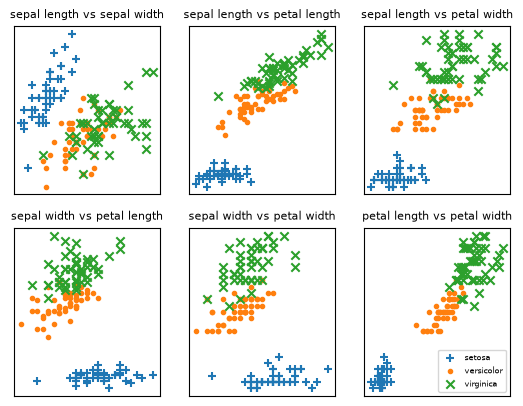

In [ ]:
# data points are 4-d making hard to plot
# Instead, we can look at the scatterplots for each of the 6 pairs of measurement
# scatterplots are a good way to visualize the relationship between two variables, and can help us see how well-separated the different species are based on their measurements.

from matplotlib import pyplot as plt

metrics = ['sepal length', 'sepal width', 'petal length', 'petal width']
pairs = [
    (i, j) 
    for i in range(4) 
    for j in range(4) 
    if i < j
]
marks = ['+', '.', 'x'] # we have 3 classes, so 3 markers

fig, ax = plt.subplots(2, 3)

for row in range(2):
    for col in range(3):
        i, j = pairs[3 * row + col]
        ax[row][col].set_title(f"{metrics[i]} vs {metrics[j]}", fontsize=8)
        ax[row][col].set_xticks([])
        ax[row][col].set_yticks([])

        for mark, (species, points) in zip(marks, points_by_species.items()):
            xs = [point[i] for point in points]
            ys = [point[j] for point in points]
            ax[row][col].scatter(xs, ys, marker=mark, label=species)

ax[-1][-1].legend(loc='lower right', prop={'size': 6})
plt.show()

In [19]:
# Predict Species based on Nearest Neighbour

import random
from scratch.machine_learning import split_data

random.seed(12)
iris_train, iris_test = split_data(iris_data, 0.70)

assert len(iris_train) == 0.7 * 150
assert len(iris_test) == 0.3 * 150 

In [20]:
# The training ser will be the "neighbours" that we'll use to classify the points in the test set.
# We get to choose 'k', the number of neighbours who get to vote.
# Too small (say k=1) and we let outliers have too much influence, and too large(say k=105), and we predict the most common class in the dataset

# In real application(and with more data), we might create a separate validation set and use it to choose 'k'. Here we'll just use k = 5:

confusion_matrix: Dict[tuple[str, str], int] = defaultdict(int)
num_correct = 0

for iris in iris_test:
    predicted = knn_classify(5, iris_train, iris.point)
    actual = iris.label

    if predicted == actual:
        num_correct += 1

    confusion_matrix[(predicted, actual)] += 1

pct_correct = num_correct /len(iris_test)
print(pct_correct, confusion_matrix)



0.9777777777777777 defaultdict(<class 'int'>, {('setosa', 'setosa'): 13, ('versicolor', 'versicolor'): 15, ('virginica', 'virginica'): 16, ('virginica', 'versicolor'): 1})


In [ ]:
# THE CURSE OF DIMENSIONALITY

# - The iris dataset is 4-dimensional, which is already hard to visualize, but not too bad for KNN
# - As the number of dimensions increases, the volume of the space increases exponentially, and the data points become sparse. This sparsity makes it difficult for KNN to find meaningful nearest neighbors, as all points tend to be far away from each other in high-dimensional spaces. This phenomenon is known as the "curse of dimensionality."

# - To use nearest neighbors effectively in high-dimensional spaces, we often need to reduce the dimensionality of the data using techniques like Principal Component Analysis (PCA) or t-Distributed Stochastic Neighbor Embedding (t-SNE) before applying KNN.